# A visual tour of square packing

### What the pictures say that the formulas don't

The companion notebook (`packing_unit_squares.ipynb`) does the mathematics.
This one is about **seeing** it. Every figure below is drawn from real
coordinates and recomputed as you run the cells — nothing is a stock image, and
the numbers printed under each panel are measured from the drawing itself.

Four things are worth looking at:

1. **The grid staircase** — why the container grows in sudden steps of one.
2. **Perfect squares** — the only packings that fill their box exactly.
3. **n = 5** — the smallest case where tilting wins, and by how much.
4. **n = k² − 1 and k² − 2** — the "mutilated chessboard": knock one or two
   cells out of a grid and you never need a bigger box.

Colours are only there to separate squares from each other. Grey is empty
container — the waste you are paying for.

## 0. The drawing code

Pillow only, no matplotlib (so it runs on a bare Kaggle kernel). `render()`
draws a list of packings **at one common scale** — that is the whole point:
a packing with $L = 2.707$ must look visibly smaller than one with $L = 3.000$,
otherwise the picture is decorative rather than informative.

You can skip these cells; the tour starts below.

#### Imports

In [1]:
import math

import numpy as np
from PIL import Image, ImageDraw, ImageFont

#### Geometry: corners, container side, score

In [2]:
SQ = [(0.0, 1.0), (1.0, 1.0), (1.0, 0.0), (0.0, 0.0)]  # not used, see below
_HALF = np.array([[-0.5, -0.5], [0.5, -0.5], [0.5, 0.5], [-0.5, 0.5]])


def corners(xy, th):
    """(n, 4, 2) corners of n unit squares centred at xy, rotated by th."""
    xy = np.asarray(xy, dtype=float)
    th = np.asarray(th, dtype=float)
    c, s = np.cos(th), np.sin(th)
    x = xy[:, 0:1] + c[:, None] * _HALF[:, 0] - s[:, None] * _HALF[:, 1]
    y = xy[:, 1:2] + s[:, None] * _HALF[:, 0] + c[:, None] * _HALF[:, 1]
    return np.stack([x, y], axis=-1)


def side(xy, th):
    """Side of the tightest axis-aligned square around the packing."""
    p = corners(xy, th).reshape(-1, 2)
    return float(max(np.ptp(p[:, 0]), np.ptp(p[:, 1])))


def score(L, n):
    return L / math.sqrt(n) - 1.0

#### Packings worth looking at (grid, the n=5 optimum, mutilated grids)

In [3]:
def grid(n):
    """The trivial packing: ceil(sqrt n) x ceil(sqrt n)."""
    k = int(math.ceil(math.sqrt(n) - 1e-12))
    idx = np.arange(n)
    xy = np.stack([idx % k + 0.5, idx // k + 0.5], axis=-1).astype(float)
    return xy, np.zeros(n)


def optimal5():
    """The proved-optimal packing of 5 unit squares, L = 2 + sqrt(2)/2.

    Four unit squares sit in the four corners of the container; the fifth is
    rotated by 45 degrees and fills the middle.  Each corner square touches the
    central diamond at exactly one point -- its inner corner lands on an edge
    of the diamond -- which is why the gap is sqrt(2)/2 and not more.
    """
    L = 2.0 + 0.5 ** 0.5
    xy = np.array(
        [[0.5, 0.5], [L - 0.5, 0.5], [0.5, L - 0.5], [L - 0.5, L - 0.5],
         [L / 2.0, L / 2.0]]
    )
    th = np.array([0.0, 0.0, 0.0, 0.0, math.pi / 4.0])
    return xy, th


def mutilated(k=3, holes=()):
    """The k x k grid with some cells removed: the n = k^2 - |holes| family.

    Removing a cell never increases the bounding box, so these pack into a
    k x k square -- and for |holes| <= 2 that is provably optimal.
    """
    cells = [(i, j) for i in range(k) for j in range(k) if (i, j) not in holes]
    xy = np.array([[i + 0.5, j + 0.5] for i, j in cells], dtype=float)
    return xy, np.zeros(len(cells))


def rotated_block(k=2, angle=0.0):
    """A k x k grid of unit squares, the whole block rotated by `angle`."""
    xy, th = grid(k * k)
    xy = xy - (k / 2.0)
    c, s = math.cos(angle), math.sin(angle)
    R = np.array([[c, -s], [s, c]])
    return xy @ R.T + (k / 2.0), np.full(k * k, angle)

#### Drawing

In [4]:
PALETTE = [
    (219, 68, 55), (66, 133, 244), (244, 180, 0), (15, 157, 88),
    (171, 71, 188), (0, 172, 193), (255, 112, 67), (124, 179, 66),
]
INK = (32, 33, 36)
GREY = (120, 122, 128)
LIGHT = (214, 216, 220)


def _font(size, bold=False):
    try:
        return ImageFont.load_default(size=size)
    except TypeError:                       # Pillow < 10
        return ImageFont.load_default()


def render(panels, path, cols=None, cell=(330, 372), margin=24,
           background=(255, 255, 255)):
    """Draw several packings side by side at a common scale.

    `panels` is a list of dicts: xy, th, label (str), note (str, optional),
    and optionally `waste` (bool) to shade the unused part of the container.
    """
    panels = list(panels)
    cols = cols or len(panels)
    rows = int(math.ceil(len(panels) / cols))
    maxL = max(side(p["xy"], p["th"]) for p in panels)

    # one scale for every panel: that is the whole point of the figure
    s = (cell[0] - 2 * margin) / maxL
    row_h = margin + 6 + maxL * s + 46 + margin

    W, H = cols * cell[0], int(rows * row_h)
    img = Image.new("RGB", (W, H), background)
    d = ImageDraw.Draw(img)
    f_lab, f_note = _font(15), _font(13)

    for idx, p in enumerate(panels):
        r, c = divmod(idx, cols)
        x0, y0 = c * cell[0], r * row_h
        xy, th = np.asarray(p["xy"], float), np.asarray(p["th"], float)
        n = len(xy)
        L = side(xy, th)

        # put the packing's bounding box at the panel origin
        pts = corners(xy, th).reshape(-1, 2)
        lo = pts.min(axis=0)
        xy = xy - lo

        ox = x0 + (cell[0] - L * s) / 2.0
        oy = y0 + margin + 6

        def P(px, py):
            return (ox + px * s, oy + (L - py) * s)

        layer = Image.new("RGBA", (W, H), (0, 0, 0, 0))
        dl = ImageDraw.Draw(layer)

        if p.get("waste"):
            dl.rectangle([P(0, L), P(L, 0)], fill=LIGHT + (255,))

        for i in range(n):
            poly = [P(px, py) for px, py in corners(xy[i:i + 1], th[i:i + 1])[0]]
            col = PALETTE[i % len(PALETTE)]
            dl.polygon(poly, fill=col + (150,), outline=col + (255,))
        img = Image.alpha_composite(img.convert("RGBA"), layer).convert("RGB")
        d = ImageDraw.Draw(img)

        # redraw crisp outlines on top of the alpha
        for i in range(n):
            poly = [P(px, py) for px, py in corners(xy[i:i + 1], th[i:i + 1])[0]]
            d.line(poly + [poly[0]], fill=INK, width=2, joint="curve")

        d.rectangle([P(0, L), P(L, 0)], outline=INK, width=2)

        ly = oy + maxL * s + 10
        d.text((x0 + margin, ly), p["label"], font=f_lab, fill=INK)
        if p.get("note"):
            d.text((x0 + margin, ly + 19), p["note"], font=f_note, fill=GREY)

    img.save(path)
    return path


def figure_n5(panels, path):
    return render(panels, path, cols=len(panels), cell=(380, 430))


def figure_gallery(items, path, cols=4):
    return render(items, path, cols=cols, cell=(250, 280), margin=18)


def plot_L_vs_n(ns, L_grid, L_bound, known, path, W=1120, H=560, PAD=78):
    """Container side L as a function of n: the bound, the grid, the records."""
    img = Image.new("RGB", (W, H), "white")
    d = ImageDraw.Draw(img)
    f, fs = _font(17), _font(14)
    ymax = max(L_grid) * 1.05

    def X(n):
        return PAD + (n - 1) / (ns[-1] - 1) * (W - 2 * PAD)

    def Y(v):
        return H - PAD - v / ymax * (H - 2 * PAD)

    for v in range(0, int(ymax) + 1, 2):
        d.line([(PAD, Y(v)), (W - PAD, Y(v))], fill=(232, 232, 236), width=1)
        d.text((PAD - 34, Y(v) - 8), str(v), font=fs, fill=GREY)

    # the area bound
    d.line([(X(n), Y(v)) for n, v in zip(ns, L_bound)], fill=(60, 60, 66), width=2)
    # the grid staircase
    d.line([(X(n), Y(v)) for n, v in zip(ns, L_grid)], fill=(30, 90, 200), width=2)
    # published records
    for n, v in known.items():
        if n <= ns[-1]:
            d.ellipse([X(n) - 4, Y(v) - 4, X(n) + 4, Y(v) + 4],
                      fill=(200, 40, 40), outline="white")

    d.text((PAD, 22), "Container side L(n): the area bound, the grid staircase, the records",
           font=f, fill=INK)
    d.text((PAD, 48), "black = sqrt(n) (area bound)   blue = trivial grid   red = best known packing",
           font=fs, fill=GREY)
    for n in [1, 25, 50, 75, 100]:
        if n <= ns[-1]:
            d.line([(X(n), Y(0)), (X(n), Y(0) + 5)], fill=(60, 60, 66), width=1)
            d.text((X(n) - 8, Y(0) + 9), str(n), font=fs, fill=GREY)
    img.save(path)
    return path

In [5]:
# Display a PNG inline (rather than as a separate file to open).
def show_png(path):
    from IPython.display import Image, display
    display(Image(filename=path))

## 1. A gallery, n = 1 … 12

Every packing here is the **trivial grid**: lay the squares out in a
$\lceil\sqrt n\rceil \times \lceil\sqrt n\rceil$ block and shrink-wrap.

Watch the container instead of the squares. It stays at 2 for $n=2,3,4$, jumps
to 3 for $n=5\ldots9$, jumps to 4 at $n=10$. The jump happens one puzzle *after*
the grid fills up, and that jump is the expensive part of this competition.

Also note the grey: at $n=5$ you are paying for nine cells and using five.

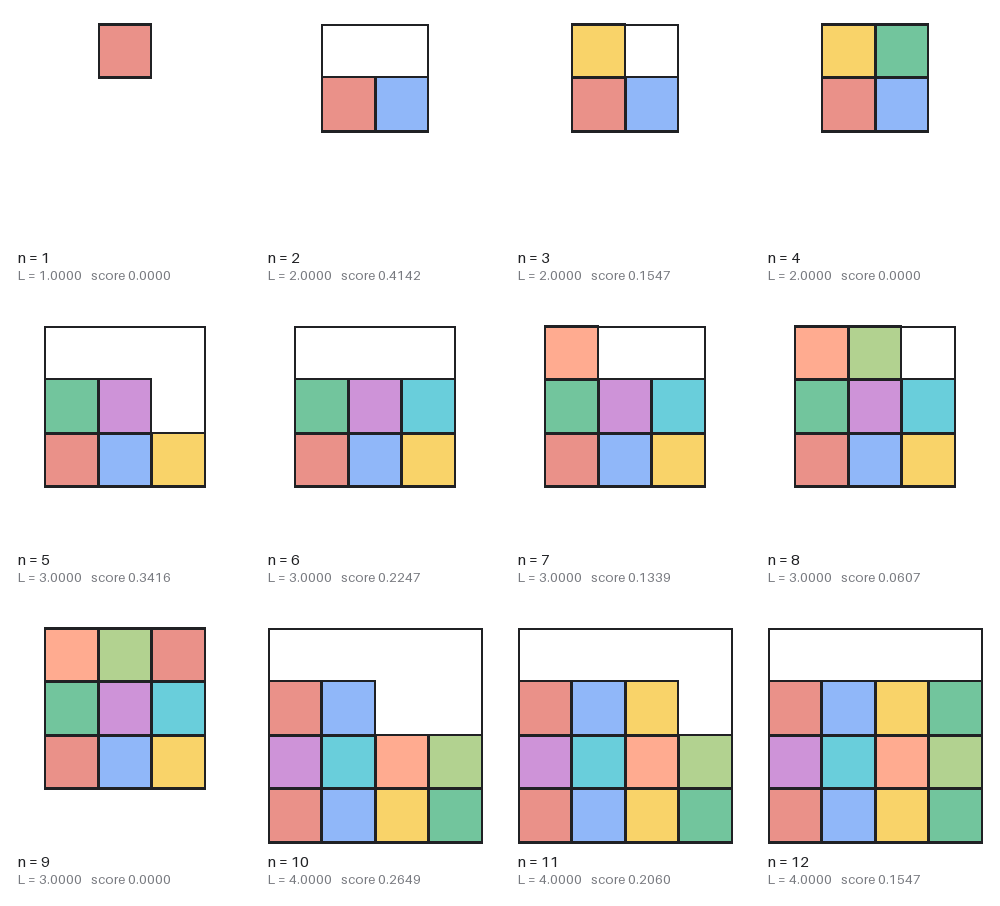

In [6]:
from pathlib import Path
Path("figures").mkdir(exist_ok=True)

items = []
for n in range(1, 13):
    xy, th = grid(n)
    L = side(xy, th)
    items.append({"xy": xy, "th": th, "label": f"n = {n}",
                  "note": f"L = {L:.4f}   score {score(L, n):.4f}"})
show_png(render(items, "figures/gallery.png", cols=4, cell=(250, 280), margin=18))

## 2. Perfect squares: the only packings that fill the box

$n = 4, 9, 16$: the grid *is* the optimum, the container is exactly
$\sqrt n \times \sqrt n$, and the score is **exactly 0**.

There is no grey in these panels, and there cannot be: $n$ unit squares have
area $n$, a square of side $\sqrt n$ has area $n$, so a packing with
$L=\sqrt n$ uses every bit of the box. Any packing with a visible gap has
$L > \sqrt n$ and a positive score.

Since only 31 of the first 1000 values of $n$ are perfect squares, only 31
puzzles can ever score exactly 0 — those are the `1.000000000000000` entries
people post.

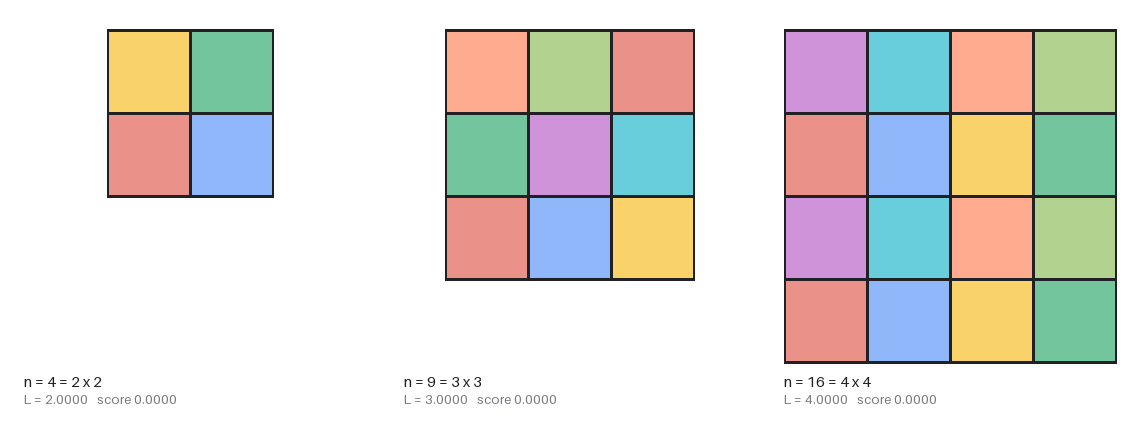

In [7]:
items = []
for k in (2, 3, 4):
    xy, th = grid(k * k)
    L = side(xy, th)
    items.append({"xy": xy, "th": th, "label": f"n = {k*k} = {k} x {k}",
                  "note": f"L = {L:.4f}   score {score(L, k*k):.4f}"})
show_png(render(items, "figures/perfect-squares.png", cols=3, cell=(380, 430)))

## 3. n = 5: the smallest puzzle where tilting wins

This is the first genuinely interesting case, and the one where human intuition
beats every naive search.

### The optimal packing

Four unit squares sit in the four corners of the container. The fifth is
rotated by $45^\circ$ and dropped in the middle. Each corner square touches the
central diamond at **exactly one point** — its inner corner lands on an edge of
the diamond — and that tangency is what fixes the container size:

$$L = 2 + \frac{\sqrt 2}{2} = 2.7071\ldots$$

Read the construction off the picture: if the four corner squares are unit
squares in the corners of an $L \times L$ box, the middle gap has width
$L - 2$ on each side. A unit square rotated by $45^\circ$ has axis-aligned
extent $\sqrt 2$, and its diamond shape lets its four vertices poke into the
four gaps.
The gap closes when $L - 2 = \sqrt2/2$, i.e. $L = 2 + \sqrt2/2$. Göbel proved in
1979 that nothing does better.

### Why the search stops short

The middle panel is what the shrink-wrap optimiser in the companion notebook
actually produces. It finds the *right idea* — it rotates a square and buries it
in the middle — but it cannot land on the exact tangency, so it pays about 3%
extra in $L$ and loses $0.035$ of score.

grid      L = 3.000000   score 0.341641
search    L = 2.784841   score 0.245419
optimal   L = 2.707107   score 0.210655
area bound  sqrt(5) = 2.236068   (unreachable: 5 is not a perfect square)


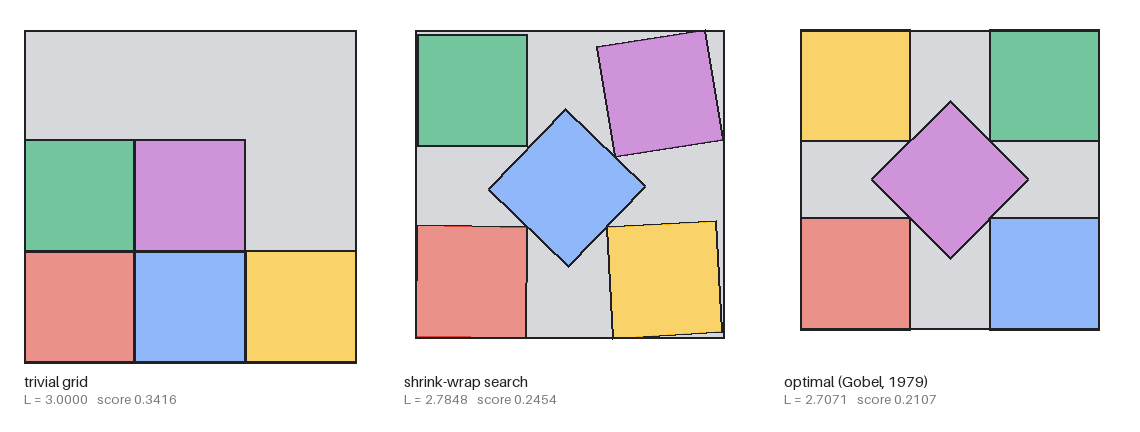

In [8]:
SEARCH5_XY = [[0.504640783303, 0.509353949447], [1.365685213187, 1.355608932034], [2.246583678172, 0.528102555901], [0.511349135727, 2.238797019238], [2.206606600898, 2.211355447084]]
SEARCH5_TH = [-0.009325180941, 0.801302812689, 0.057914029371, -0.000163605179, 0.160514917322]

# Four corner squares + one diamond. L = 2 + sqrt(2)/2.
GRID5, GRID5_TH = grid(5)
OPT5, OPT5_TH = optimal5()

# a few % worse than optimal, but the right topology -- found by the
# shrink-wrap search in packing_unit_squares.ipynb
SEARCH5 = np.array(SEARCH5_XY)
SEARCH5_TH = np.array(SEARCH5_TH)

print(f"grid      L = {side(GRID5, GRID5_TH):.6f}   score {score(side(GRID5, GRID5_TH), 5):.6f}")
print(f"search    L = {side(SEARCH5, SEARCH5_TH):.6f}   score {score(side(SEARCH5, SEARCH5_TH), 5):.6f}")
print(f"optimal   L = {side(OPT5, OPT5_TH):.6f}   score {score(side(OPT5, OPT5_TH), 5):.6f}")
print(f"area bound  sqrt(5) = {np.sqrt(5):.6f}   (unreachable: 5 is not a perfect square)")

panels = [
    {"xy": GRID5, "th": GRID5_TH, "label": "trivial grid",
     "note": f"L = 3.0000   score {score(3.0, 5):.4f}", "waste": True},
    {"xy": SEARCH5, "th": SEARCH5_TH, "label": "shrink-wrap search",
     "note": f"L = {side(SEARCH5, SEARCH5_TH):.4f}   score {score(side(SEARCH5, SEARCH5_TH), 5):.4f}",
     "waste": True},
    {"xy": OPT5, "th": OPT5_TH, "label": "optimal (Gobel, 1979)",
     "note": f"L = {side(OPT5, OPT5_TH):.4f}   score {score(side(OPT5, OPT5_TH), 5):.4f}",
     "waste": True},
]
show_png(render(panels, "figures/n5-three-ways.png", cols=3, cell=(380, 430)))

### Check the tangency yourself

The claim "each corner square touches the diamond at exactly one point" is easy
to verify analytically. The inner corner of the bottom-left square is at
$(1,1)$; the diamond's lower-left edge runs along $x + y = 2$. That line passes
through $(1,1)$ exactly, and the square sits in $x + y \le 2$ — so the only
contact is the single point $(1,1)$. Repeat for the other three corners and the
packing is proved legal.

The cell below measures it instead. Note the subtlety it has to get right: the
closest approach between two squares is a **point-to-edge** distance, not
vertex-to-vertex — the tangency point here lies in the *interior* of the
diamond's edge, so a naive corner-to-corner computation reports $0.5$ and misses
the contact entirely.

In [9]:
def _pt_seg(p, a, b):
    # distance from point p to the segment a-b
    ab = b - a
    t = np.clip(np.dot(p - a, ab) / np.dot(ab, ab), 0.0, 1.0)
    return np.linalg.norm(p - (a + t * ab))


def poly_distance(A, B):
    # For convex polygons the closest pair is always vertex-to-edge, so
    # minimising the 8 vertices against the 4 edges of the other body is exact.
    best = np.inf
    for i in range(4):
        for j in range(4):
            best = min(best, _pt_seg(A[i], B[j], B[(j + 1) % 4]))
            best = min(best, _pt_seg(B[i], A[j], A[(j + 1) % 4]))
    return best


def gaps(xy, th):
    # Distance from each square to its nearest neighbour: 0 = touching.
    # A legal packing never goes negative.
    p = corners(xy, th)
    n = len(xy)
    out = []
    for i in range(n):
        best = np.inf
        for j in range(n):
            if i != j:
                best = min(best, poly_distance(p[i], p[j]))
        out.append(best)
    return np.array(out)


print("distance from each square to its nearest neighbour (0 = in contact)")
g_opt = gaps(OPT5, OPT5_TH)
g_grid = gaps(GRID5, GRID5_TH)
g_search = gaps(SEARCH5, SEARCH5_TH)
for name, g in [("optimal n=5", g_opt), ("grid    n=5", g_grid),
                ("search  n=5", g_search)]:
    print(f"  {name} : {np.round(np.maximum(g, 0), 6)}")

print()
print(f"optimal: largest slack {g_opt.max():.2e}  -> every square is in contact.")
print(f"search : largest slack {g_search.max():.2e}  -> {np.sum(g_search > 1e-4)} of 5 "
      "squares still float free.")
print()
print("That slack is the 2.8% of L the search pays. A rigid packing has no slack")
print("to spend: every degree of freedom is pinned by a contact, so the contacts")
print("themselves determine L. Finding *which* contacts to force is the hard part.")

distance from each square to its nearest neighbour (0 = in contact)
  optimal n=5 : [0. 0. 0. 0. 0.]
  grid    n=5 : [0. 0. 0. 0. 0.]
  search  n=5 : [4.200e-05 1.400e-05 1.989e-03 2.112e-02 1.400e-05]

optimal: largest slack 0.00e+00  -> every square is in contact.
search : largest slack 2.11e-02  -> 2 of 5 squares still float free.

That slack is the 2.8% of L the search pays. A rigid packing has no slack
to spend: every degree of freedom is pinned by a contact, so the contacts
themselves determine L. Finding *which* contacts to force is the hard part.


## 4. The $n = k^2-1$ and $k^2-2$ families

Take a $3\times3$ grid and knock out one or two cells. The bounding box does not
grow — it is still $3 \times 3$ — so $n=8$ and $n=7$ pack into a container of
side 3, exactly like $n=9$ does.

This is not a curiosity, it is a theorem: $s(k^2) = s(k^2-1) = s(k^2-2) = k$.
For $n \le 1000$ that settles $31 + 30 + 30 = 91$ puzzles — they are already at
their optimum, and no amount of search can improve them.

The grey holes in these pictures are *allowed*: you are not required to fill the
container, only to fit inside it.

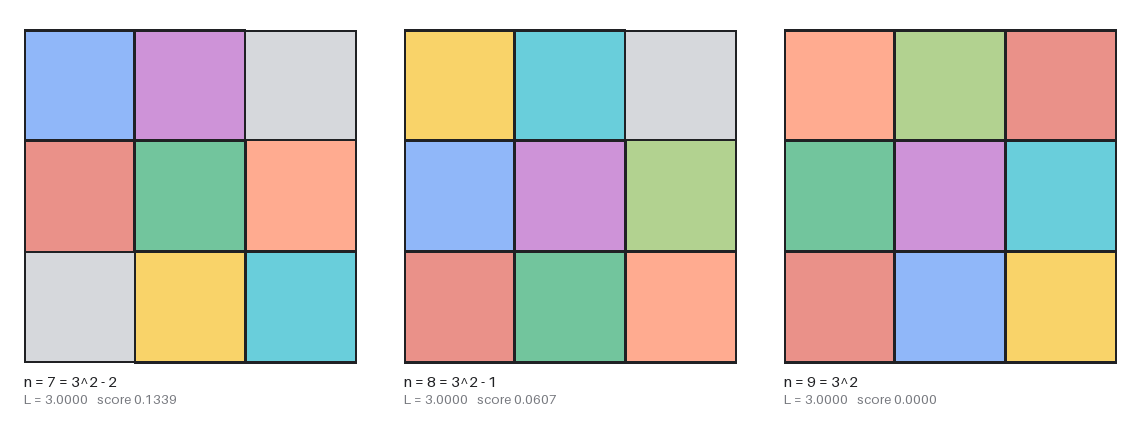

In [10]:
xy7, th7 = mutilated(3, holes=((0, 0), (2, 2)))
xy8, th8 = mutilated(3, holes=((2, 2),))
xy9, th9 = grid(9)

panels = []
for xy, th, lab in [(xy7, th7, "n = 7 = 3^2 - 2"),
                    (xy8, th8, "n = 8 = 3^2 - 1"),
                    (xy9, th9, "n = 9 = 3^2")]:
    L = side(xy, th)
    panels.append({"xy": xy, "th": th, "label": lab,
                   "note": f"L = {L:.4f}   score {score(L, len(xy)):.4f}",
                   "waste": True})
show_png(render(panels, "figures/k2-minus.png", cols=3, cell=(380, 430)))

## 5. The container side as a function of $n$

Same information as the gallery, all at once.

* **Black** is $\sqrt n$ — the area bound, unattainable except at perfect
  squares.
* **Blue** is the trivial grid: a staircase that touches the black curve at
  $n = 1,4,9,16,\ldots$ and jumps one level right after each of them.
* **Red** is the best packing anybody has published, for $n \le 20$. It ducks
  under the staircase but stays above the bound.

The vertical gap between blue and black is the score you are paying. For $n$
just above a perfect square that gap is $\approx 1$, i.e. a full unit of
container; for $n$ just below one it is almost nothing. That asymmetry is why
"$n = k^2+1$" puzzles are where the leaderboard is won.

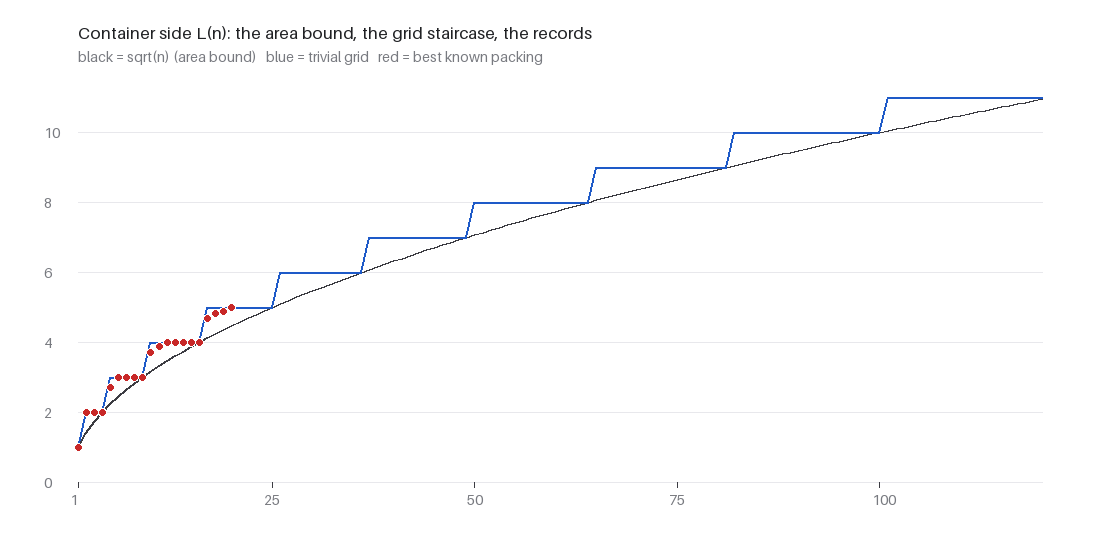

In [11]:
ns = list(range(1, 121))
L_grid = [side(*grid(n)) for n in ns]
L_bound = [np.sqrt(n) for n in ns]

KNOWN = {1: 1.0, 2: 2.0, 3: 2.0, 4: 2.0, 5: 2 + 0.5 ** 0.5, 6: 3.0, 7: 3.0,
         8: 3.0, 9: 3.0, 10: 3 + 0.5 ** 0.5, 11: 3.87708359, 12: 4.0,
         13: 4.0, 14: 4.0, 15: 4.0, 16: 4.0, 17: 4.67553009,
         18: 4.822875655, 19: 4.885618083, 20: 5.0}

show_png(plot_L_vs_n(ns, L_grid, L_bound, KNOWN, "figures/L-vs-n.png"))

## 6. Draw your own

Drop in any list of centres and angles. This is the quickest way to sanity-check
a submission visually before you upload it — an overlap that is invisible in a
CSV is obvious in a picture.

```python
panels = [{"xy": my_xy, "th": my_th, "label": "n = 37, mine",
           "note": f"L = {side(my_xy, my_th):.4f}"}]
show_png(render(panels, "figures/mine.png"))
```

rotating a block that already fills its box only makes the box bigger:
  axis-aligned L = 3.000000
  rotated 20d  L = 3.845138


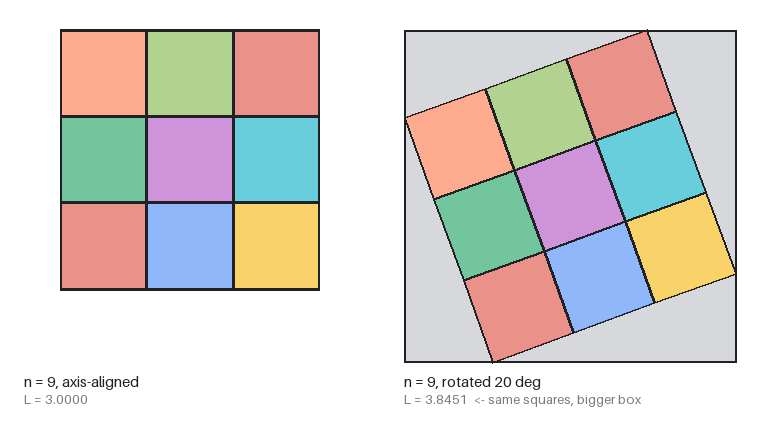

In [12]:
# a deliberately silly example: the same 3x3 grid rotated by 20 degrees.
# It no longer fits in 3x3 -- the corners stick out -- so L grows.
a = np.deg2rad(20)
c, s = np.cos(a), np.sin(a)
R = np.array([[c, -s], [s, c]])
base, _ = grid(9)
spun = (base - 1.5) @ R.T + 1.5

panels = [
    {"xy": base, "th": np.zeros(9), "label": "n = 9, axis-aligned",
     "note": f"L = {side(base, np.zeros(9)):.4f}", "waste": True},
    {"xy": spun, "th": np.full(9, a), "label": "n = 9, rotated 20 deg",
     "note": f"L = {side(spun, np.full(9, a)):.4f}  <- same squares, bigger box",
     "waste": True},
]
show_png(render(panels, "figures/rotated.png", cols=2, cell=(380, 430)))
print("rotating a block that already fills its box only makes the box bigger:")
print(f"  axis-aligned L = {side(base, np.zeros(9)):.6f}")
print(f"  rotated 20d  L = {side(spun, np.full(9, a)):.6f}")

That last pair is a useful warning. Rotation is not free: it lets a square reach
into a gap, but it also sweeps out a bigger bounding box ($\sqrt2$ instead of
$1$ at $45^\circ$). Every tilted packing in the record tables is a *negotiated*
improvement — the tilt buys space in one direction and pays for it in another.
That is what makes the optimisation non-obvious, and it is why the search in the
companion notebook stalls where it does.

## Where to go next

* **The mathematics** — `packing_unit_squares.ipynb` proves that score $=0$ if and
  only if $n$ is a perfect square, tabulates what is known for $n\le20$, and
  builds the validator, the optimiser and the submission writer.
* **The frontier** — [squaremath.org](https://squaremath.org/frontier.html)
  publishes the best known packing and best lower bound for every $n$, with
  attribution.
* **The written version** — `README.md` in this folder is the same story in
  prose, with these figures embedded.